In [4]:
import pandas as pd

df = pd.read_csv("../data/heart_disease.csv")

In [5]:
df["dataset"].value_counts(dropna=False)

dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

In [6]:
df.groupby("dataset")["num"].value_counts(normalize=True).unstack()

num,0,1,2,3,4
dataset,,,,,
Cleveland,0.542763,0.180921,0.118421,0.115132,0.042763
Hungary,0.638225,0.361775,NaN,NaN,NaN
Switzerland,0.065041,0.390244,0.260163,0.243902,0.040650
VA Long Beach,0.255000,0.280000,0.205000,0.210000,0.050000


In [7]:
df[df["trestbps"] <= 0]

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
753,754,55,Male,VA Long Beach,non-anginal,0.0,0.0,False,normal,155.0,False,1.5,flat,NaN,NaN,3


In [8]:
(df["trestbps"] <= 0).sum()

np.int64(1)

In [9]:
df[df["chol"] <= 0]

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
597,598,32,Male,Switzerland,typical angina,95.0,0.0,NaN,normal,127.0,False,0.7,upsloping,NaN,NaN,1
598,599,34,Male,Switzerland,asymptomatic,115.0,0.0,NaN,NaN,154.0,False,0.2,upsloping,NaN,NaN,1
599,600,35,Male,Switzerland,asymptomatic,NaN,0.0,NaN,normal,130.0,True,NaN,NaN,NaN,reversable defect,3
600,601,36,Male,Switzerland,asymptomatic,110.0,0.0,NaN,normal,125.0,True,1.0,flat,NaN,fixed defect,1
601,602,38,Female,Switzerland,asymptomatic,105.0,0.0,NaN,normal,166.0,False,2.8,upsloping,NaN,NaN,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
818,819,43,Male,VA Long Beach,asymptomatic,122.0,0.0,False,normal,120.0,False,0.5,upsloping,NaN,NaN,1
819,820,63,Male,VA Long Beach,non-anginal,130.0,0.0,True,st-t abnormality,160.0,False,3.0,flat,NaN,NaN,0
822,823,48,Male,VA Long Beach,non-anginal,102.0,0.0,NaN,st-t abnormality,110.0,True,1.0,downsloping,NaN,NaN,1
839,840,56,Male,VA Long Beach,asymptomatic,NaN,0.0,False,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,1


In [10]:
(df["chol"] <= 0).sum()

np.int64(172)

In [11]:
df[df["oldpeak"] < 0]

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
603,604,38,Male,Switzerland,non-anginal,100.0,0.0,NaN,normal,179.0,False,-1.1,upsloping,NaN,NaN,0
609,610,42,Male,Switzerland,asymptomatic,105.0,0.0,NaN,normal,128.0,True,-1.5,downsloping,NaN,NaN,1
614,615,45,Male,Switzerland,non-anginal,110.0,0.0,NaN,normal,138.0,False,-0.1,upsloping,NaN,NaN,0
615,616,46,Male,Switzerland,asymptomatic,100.0,0.0,NaN,st-t abnormality,133.0,False,-2.6,flat,NaN,NaN,1
629,630,51,Male,Switzerland,asymptomatic,130.0,0.0,NaN,normal,170.0,False,-0.7,upsloping,NaN,NaN,2
653,654,56,Male,Switzerland,non-anginal,125.0,0.0,NaN,normal,98.0,False,-2.0,flat,NaN,reversable defect,2
655,656,56,Male,Switzerland,asymptomatic,115.0,0.0,NaN,st-t abnormality,82.0,False,-1.0,upsloping,NaN,NaN,1
656,657,56,Male,Switzerland,asymptomatic,120.0,0.0,False,st-t abnormality,100.0,True,-1.0,downsloping,NaN,reversable defect,2
691,692,62,Male,Switzerland,typical angina,120.0,0.0,NaN,lv hypertrophy,134.0,False,-0.8,flat,2.0,NaN,1
694,695,62,Male,Switzerland,asymptomatic,115.0,0.0,NaN,normal,72.0,True,-0.5,flat,NaN,normal,1


In [12]:
(df["oldpeak"] < 0).sum()

np.int64(12)

In [13]:
df["num"].value_counts().sort_index()

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

In [14]:
df["num"].value_counts(normalize=True).sort_index() * 100

num
0    44.673913
1    28.804348
2    11.847826
3    11.630435
4     3.043478
Name: proportion, dtype: float64

In [15]:
missing_by_dataset = (
    df.groupby("dataset")
      .apply(lambda x: x.isnull().mean() * 100)
)

missing_by_dataset

,id,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
dataset,,,,,,,,,,,,,,,
Cleveland,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.328947,1.644737,0.986842,0.0
Hungary,0.0,0.0,0.0,0.0,0.341297,7.849829,2.730375,0.341297,0.341297,0.341297,0.000000,64.505119,98.976109,90.443686,0.0
Switzerland,0.0,0.0,0.0,0.0,1.626016,0.000000,60.975610,0.813008,0.813008,0.813008,4.878049,13.821138,95.934959,42.276423,0.0
VA Long Beach,0.0,0.0,0.0,0.0,28.000000,3.500000,3.500000,0.000000,26.500000,26.500000,28.000000,51.000000,99.000000,83.000000,0.0


In [16]:
pd.crosstab(
    df["dataset"],
    df["num"],
    normalize="index"
).round(3) * 100

num,0,1,2,3,4
dataset,,,,,
Cleveland,54.3,18.1,11.8,11.5,4.3
Hungary,63.8,36.2,0.0,0.0,0.0
Switzerland,6.5,39.0,26.0,24.4,4.1
VA Long Beach,25.5,28.0,20.5,21.0,5.0


In [17]:
df[df["chol"] <= 0][
    ["dataset", "age", "sex", "chol", "num"]
]

,dataset,age,sex,chol,num
597,Switzerland,32,Male,0.0,1
598,Switzerland,34,Male,0.0,1
599,Switzerland,35,Male,0.0,3
600,Switzerland,36,Male,0.0,1
601,Switzerland,38,Female,0.0,2
...,...,...,...,...,...
818,VA Long Beach,43,Male,0.0,1
819,VA Long Beach,63,Male,0.0,0
822,VA Long Beach,48,Male,0.0,1
839,VA Long Beach,56,Male,0.0,1


In [18]:
df[df["chol"] <= 0]["dataset"].value_counts()

dataset
Switzerland      123
VA Long Beach     49
Name: count, dtype: int64

In [19]:
df[df["trestbps"] <= 0][
    ["dataset", "age", "sex", "trestbps", "num"]
]

,dataset,age,sex,trestbps,num
753,VA Long Beach,55,Male,0.0,3


In [20]:
df[df["oldpeak"] < 0]["dataset"].value_counts()

dataset
Switzerland      11
VA Long Beach     1
Name: count, dtype: int64

# conclusion from above analysis

The results reveal an important pattern: the missingness in ca and thal is heavily concentrated in Hungary, Switzerland, and VA Long Beach, while Cleveland is almost complete. We'll account for that rather than blindly imputing everything.

Also, 172 chol = 0 values is significant, so we'll treat those as invalid/missing candidates rather than genuine cholesterol measurements. trestbps = 0 is only one row, and the 12 negative oldpeak values need investigation before changing them.

# Convert invalid values to missing

In [21]:
import numpy as np

df.loc[df["chol"] <= 0, "chol"] = np.nan

df.loc[df["trestbps"] <= 0, "trestbps"] = np.nan

In [22]:
df["target"] = (df["num"] > 0).astype(int)

In [23]:
df["target"].value_counts()

target
1    509
0    411
Name: count, dtype: int64

In [24]:
df["target"].value_counts(normalize=True) * 100

target
1    55.326087
0    44.673913
Name: proportion, dtype: float64

In [25]:
pd.crosstab(df["num"], df["target"])

target,0,1
num,,
0,411,0
1,0,265
2,0,109
3,0,107
4,0,28


In [26]:
df = df.drop(columns=["id"])

In [27]:
df.head()

,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,target
0,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,0
1,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,1
2,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,1
3,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,0
4,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,0


In [28]:
df.isnull().sum().sort_values(ascending=False)

ca          611
thal        486
slope       309
chol        202
fbs          90
oldpeak      62
trestbps     60
thalch       55
exang        55
restecg       2
dataset       0
cp            0
age           0
sex           0
num           0
target        0
dtype: int64

In [29]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalch",
    "oldpeak"
]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

print("Numerical:", numerical_features)
print("Categorical:", categorical_features)

Numerical: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
Categorical: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [30]:
for col in categorical_features:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).sort_index())


sex:
sex
Female    194
Male      726
Name: count, dtype: int64

cp:
cp
asymptomatic       496
atypical angina    174
non-anginal        204
typical angina      46
Name: count, dtype: int64

fbs:
fbs
False    692
True     138
NaN       90
Name: count, dtype: int64

restecg:
restecg
lv hypertrophy      188
normal              551
st-t abnormality    179
NaN                   2
Name: count, dtype: int64

exang:
exang
False    528
True     337
NaN       55
Name: count, dtype: int64

slope:
slope
downsloping     63
flat           345
upsloping      203
NaN            309
Name: count, dtype: int64

ca:
ca
0.0    181
1.0     67
2.0     41
3.0     20
NaN    611
Name: count, dtype: int64

thal:
thal
fixed defect          46
normal               196
reversable defect    192
NaN                  486
Name: count, dtype: int64


In [31]:
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True) * 100)

target
1    509
0    411
Name: count, dtype: int64
target
1    55.326087
0    44.673913
Name: proportion, dtype: float64


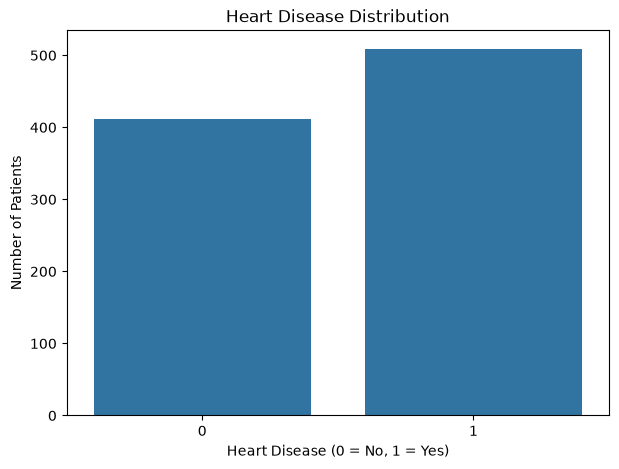

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="target")

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

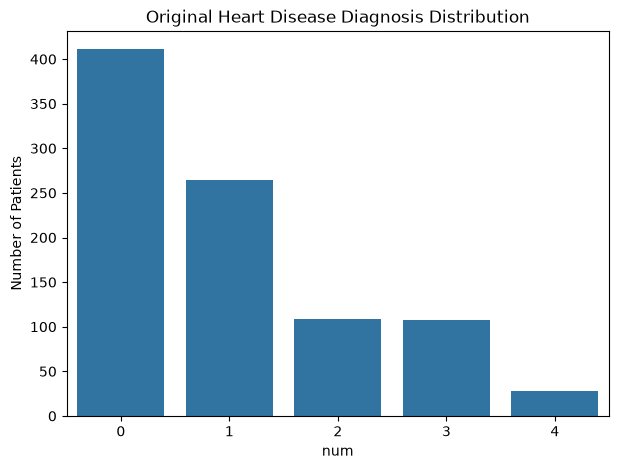

In [34]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="num")

plt.title("Original Heart Disease Diagnosis Distribution")
plt.xlabel("num")
plt.ylabel("Number of Patients")

plt.show()

In [35]:
target_by_dataset = pd.crosstab(
    df["dataset"],
    df["target"],
    normalize="index"
) * 100

target_by_dataset.round(2)

target,0,1
dataset,,
Cleveland,54.28,45.72
Hungary,63.82,36.18
Switzerland,6.50,93.50
VA Long Beach,25.50,74.50


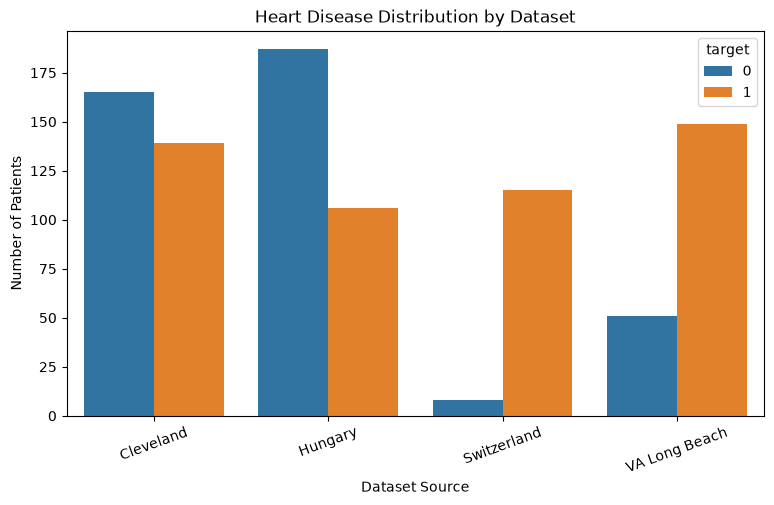

In [36]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="dataset",
    hue="target"
)

plt.title("Heart Disease Distribution by Dataset")
plt.xlabel("Dataset Source")
plt.ylabel("Number of Patients")
plt.xticks(rotation=20)

plt.show()

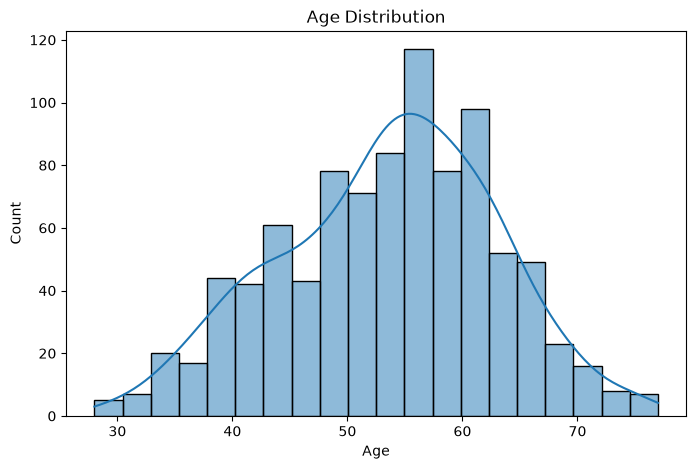

In [37]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()


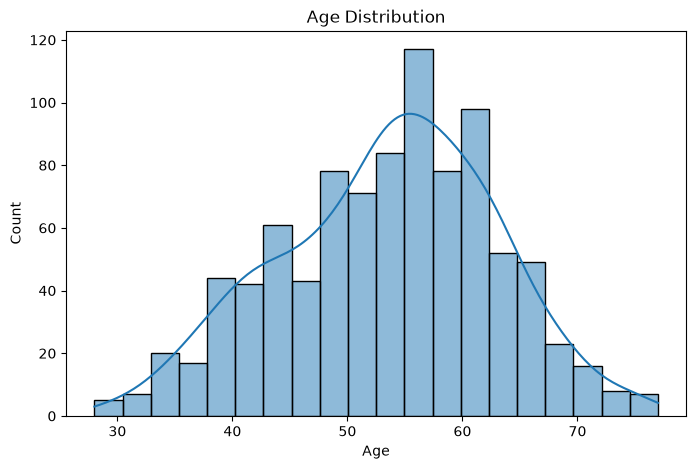

In [38]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

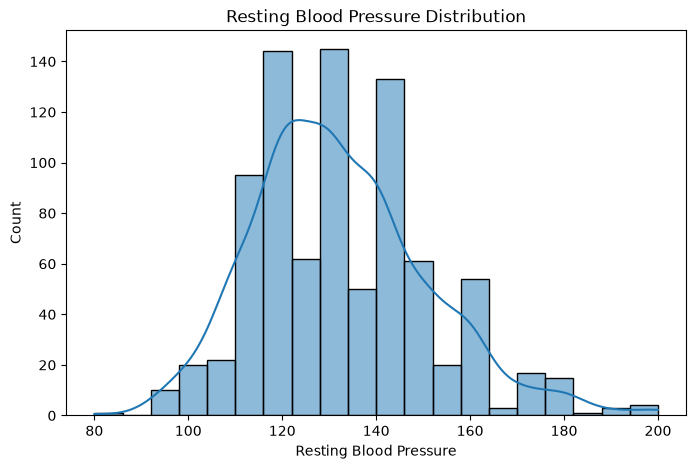

In [39]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="trestbps", bins=20, kde=True)

plt.title("Resting Blood Pressure Distribution")
plt.xlabel("Resting Blood Pressure")
plt.ylabel("Count")

plt.show()

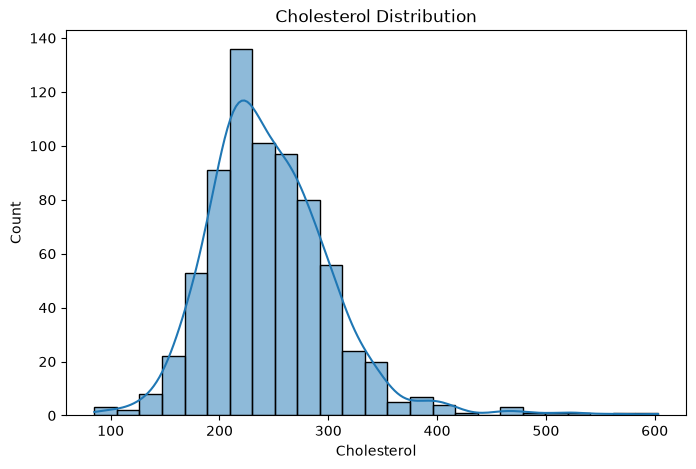

In [40]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="chol", bins=25, kde=True)

plt.title("Cholesterol Distribution")
plt.xlabel("Cholesterol")
plt.ylabel("Count")

plt.show()

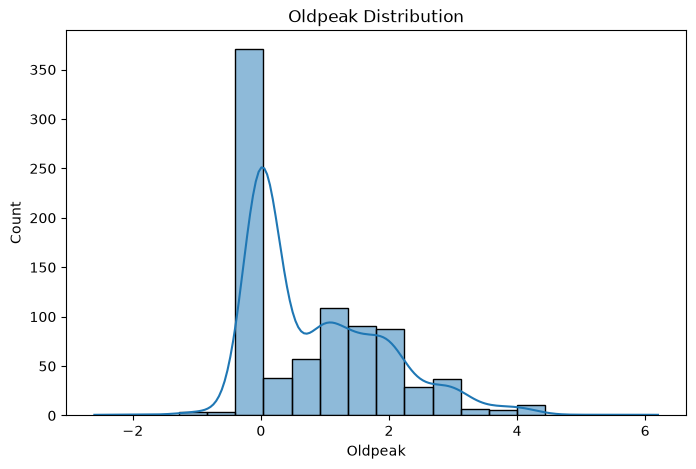

In [41]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="oldpeak", bins=20, kde=True)

plt.title("Oldpeak Distribution")
plt.xlabel("Oldpeak")
plt.ylabel("Count")

plt.show()

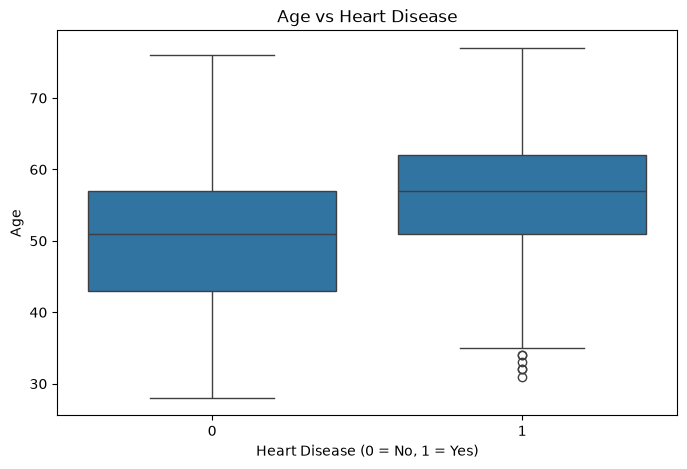

In [42]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="target", y="age")

plt.title("Age vs Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

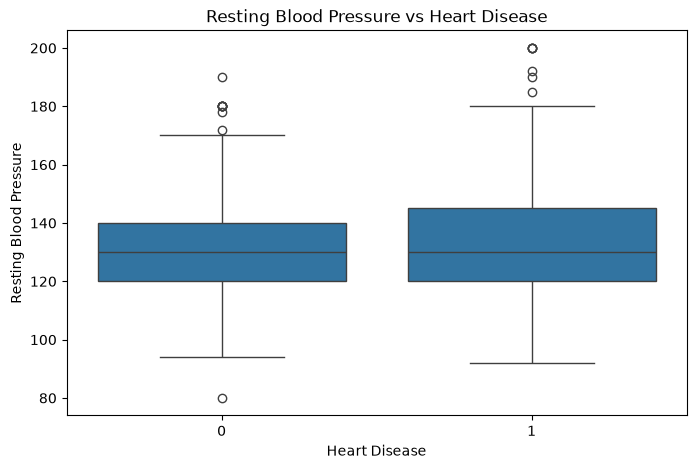

In [43]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="target", y="trestbps")

plt.title("Resting Blood Pressure vs Heart Disease")
plt.xlabel("Heart Disease")
plt.ylabel("Resting Blood Pressure")

plt.show()

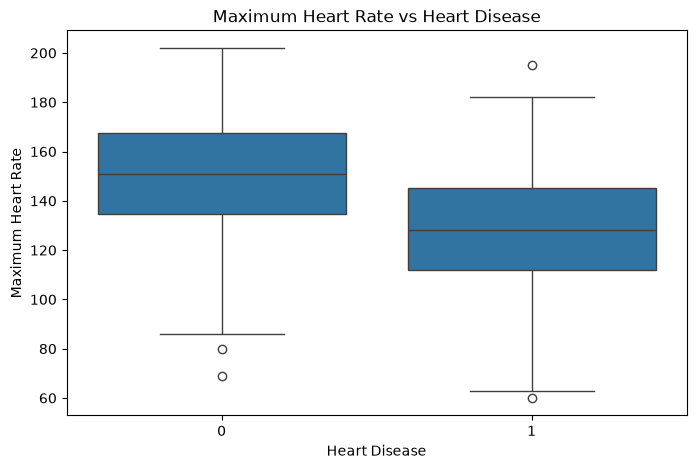

In [44]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="target", y="thalch")

plt.title("Maximum Heart Rate vs Heart Disease")
plt.xlabel("Heart Disease")
plt.ylabel("Maximum Heart Rate")

plt.show()


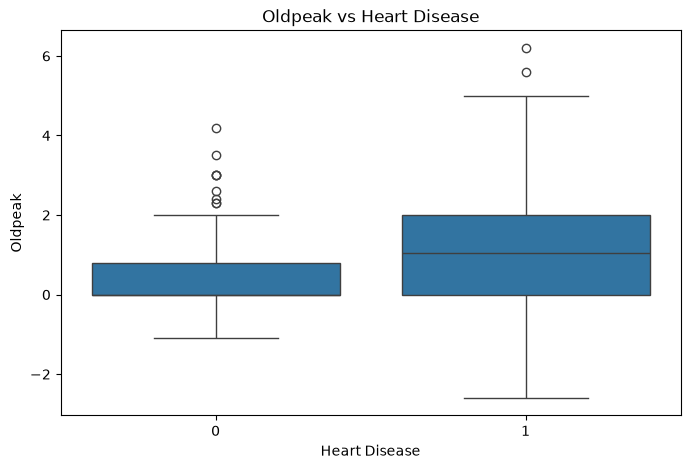

In [46]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="target", y="oldpeak")

plt.title("Oldpeak vs Heart Disease")
plt.xlabel("Heart Disease")
plt.ylabel("Oldpeak")

plt.show()

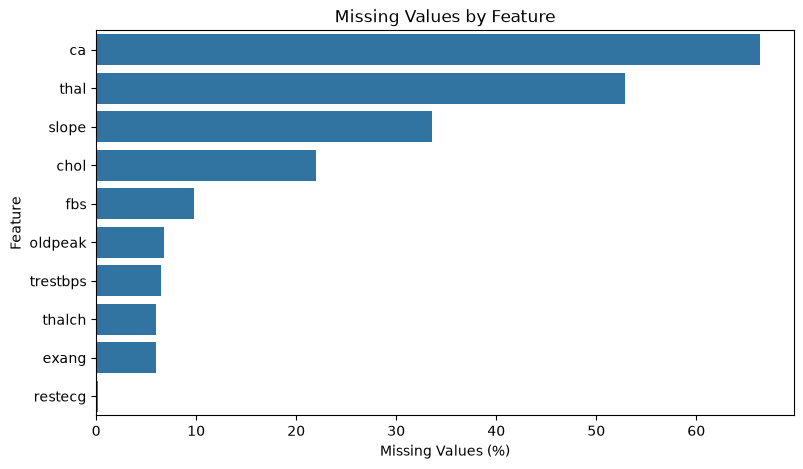

In [47]:
missing_pct = (
    df.isnull()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

missing_pct = missing_pct[missing_pct > 0]

plt.figure(figsize=(9, 5))

sns.barplot(
    x=missing_pct.values,
    y=missing_pct.index
)

plt.title("Missing Values by Feature")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")

plt.show()

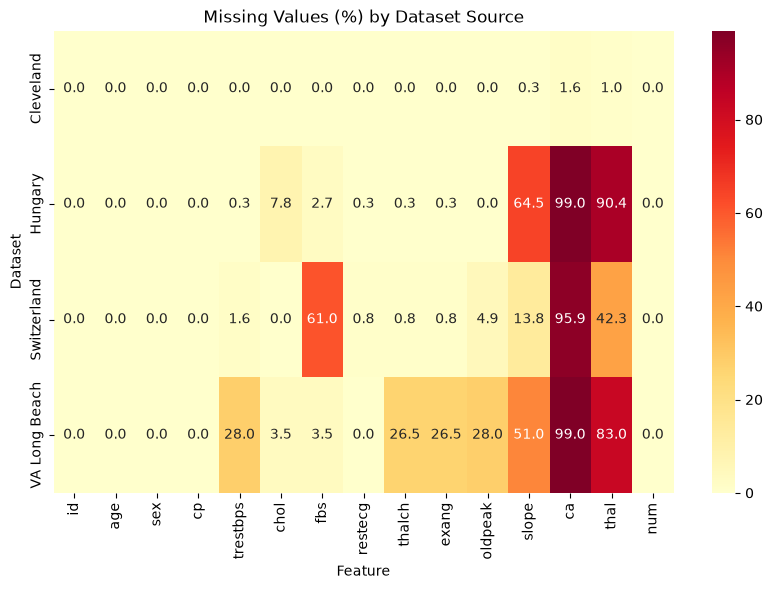

In [48]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    missing_by_dataset,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Missing Values (%) by Dataset Source")
plt.xlabel("Feature")
plt.ylabel("Dataset")

plt.show()

In [49]:
missing_target_analysis = {}

for col in df.columns:
    if df[col].isnull().sum() > 0:
        missing_target_analysis[col] = (
            df.groupby(df[col].isnull())["target"]
              .mean()
              .mul(100)
        )

missing_target_analysis

{'trestbps': trestbps
 False    54.534884
 True     66.666667
 Name: target, dtype: float64,
 'chol': chol
 False    48.189415
 True     80.693069
 Name: target, dtype: float64,
 'fbs': fbs
 False    52.168675
 True     84.444444
 Name: target, dtype: float64,
 'restecg': restecg
 False     55.228758
 True     100.000000
 Name: target, dtype: float64,
 'thalch': thalch
 False    54.797688
 True     63.636364
 Name: target, dtype: float64,
 'exang': exang
 False    54.797688
 True     63.636364
 Name: target, dtype: float64,
 'oldpeak': oldpeak
 False    54.545455
 True     66.129032
 Name: target, dtype: float64,
 'slope': slope
 False    64.320786
 True     37.540453
 Name: target, dtype: float64,
 'ca': ca
 False    46.601942
 True     59.738134
 Name: target, dtype: float64,
 'thal': thal
 False    56.912442
 True     53.909465
 Name: target, dtype: float64}

In [50]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": df.isnull().mean() * 100
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
)

missing_summary.round(2)

,missing_count,missing_percent
ca,611,66.41
thal,486,52.83
slope,309,33.59
chol,202,21.96
fbs,90,9.78
oldpeak,62,6.74
trestbps,60,6.52
thalch,55,5.98
exang,55,5.98
restecg,2,0.22


In [51]:
missing_target = []

for col in df.columns:
    if df[col].isnull().sum() > 0:
        temp = df.groupby(df[col].isnull())["target"].mean() * 100
        
        missing_target.append({
            "feature": col,
            "disease_rate_when_present": temp.get(False, np.nan),
            "disease_rate_when_missing": temp.get(True, np.nan)
        })

missing_target_df = pd.DataFrame(missing_target)

missing_target_df.round(2)

,feature,disease_rate_when_present,disease_rate_when_missing
0,trestbps,54.53,66.67
1,chol,48.19,80.69
2,fbs,52.17,84.44
3,restecg,55.23,100.00
4,thalch,54.80,63.64
5,exang,54.80,63.64
6,oldpeak,54.55,66.13
7,slope,64.32,37.54
8,ca,46.60,59.74
9,thal,56.91,53.91


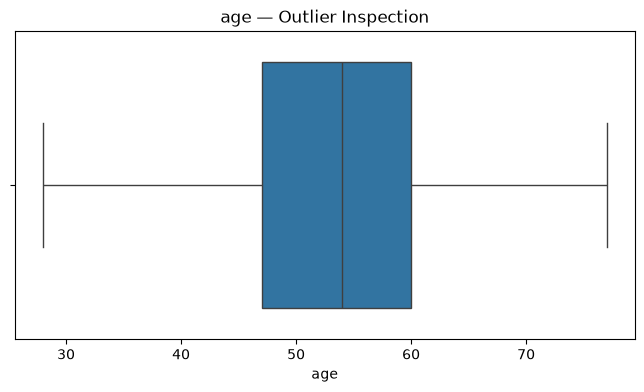

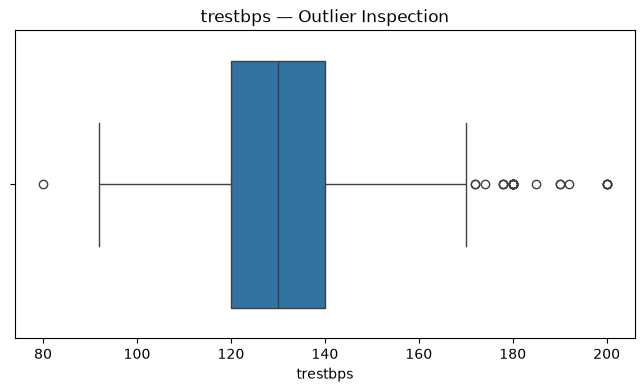

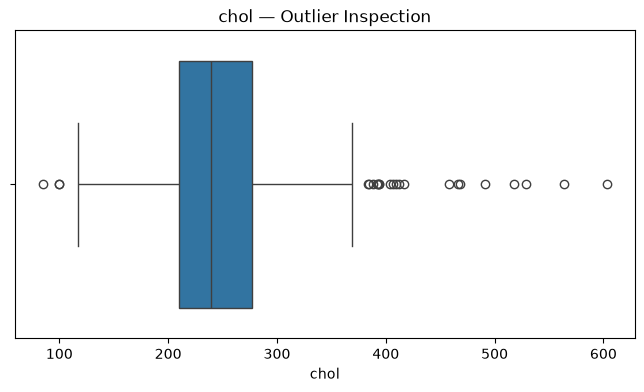

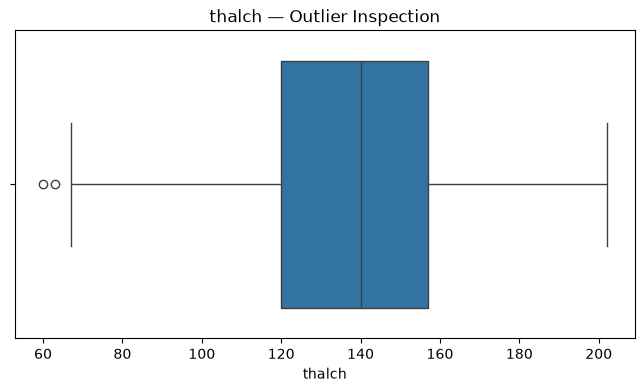

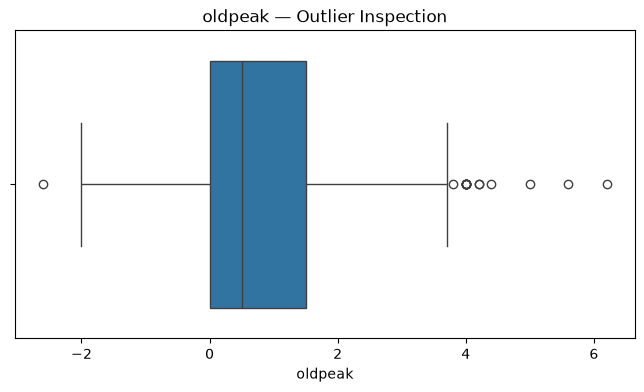

In [52]:
for col in numerical_features:
    plt.figure(figsize=(8, 4))
    
    sns.boxplot(data=df, x=col)
    
    plt.title(f"{col} — Outlier Inspection")
    plt.show()